# Cómo cambia el importe medio al ordenar los resultados de búsqueda

Pedidos de comercio electrónico de ejemplo — Camilo Fuentes

Compara el importe medio con impuestos de los primeros 10 pedidos en euros que coinciden con `clothing`. Mantén la búsqueda fija y cambia solo el criterio principal de orden: importe ascendente, importe descendente o relevancia.

Configura la conexión y ejecuta la comparación en Jupyter o en Kibana. Las tres demostraciones del anexo son opcionales y no se necesitan para realizar el experimento.

[Volver al índice](00_indice.ipynb)

## Conexión compartida

En Kibana (`http://localhost:5601`), la consola de Dev Tools envía peticiones a Elasticsearch. Python hace la misma petición directamente, sin pasar por Kibana: desde Jupyter en Docker Compose, `elasticsearch` es el nombre del servicio y `9200` su puerto. Si el kernel corre en el equipo anfitrión, usa `http://localhost:9200`.

El índice `kibana_sample_data_ecommerce` debe existir antes de ejecutar las consultas. El experimento y las demostraciones usan peticiones de solo lectura: este cuaderno no instala datos ni modifica el clúster.

In [32]:
import json
from datetime import datetime, timezone
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt

url_elasticsearch = "http://elasticsearch:9200"
indice = "kibana_sample_data_ecommerce"
ruta_busqueda = f"{indice}/_search"


def ejecutar_busqueda(cuerpo_busqueda, ruta, *, parse_float=float):
    url_busqueda = f"{url_elasticsearch.rstrip('/')}/{ruta}"
    json_busqueda = json.dumps(cuerpo_busqueda, ensure_ascii=False, indent=2)
    print(f"GET {url_busqueda}")
    print(json_busqueda)

    solicitud = Request(
        url_busqueda,
        data=json_busqueda.encode("utf-8"),
        headers={"Content-Type": "application/json"},
        method="GET",
    )
    with urlopen(solicitud, timeout=10) as respuesta:
        return json.load(respuesta, parse_float=parse_float)


def buscar_pedidos(cuerpo_busqueda):
    try:
        datos = ejecutar_busqueda(cuerpo_busqueda, ruta_busqueda)
        pedidos = [hit["_source"] for hit in datos["hits"]["hits"]]
    except HTTPError as error:
        if error.code == 404:
            print(f"No se encontró el índice {indice}. Comprueba que los datos de ejemplo estén disponibles.")
        else:
            print(f"Elasticsearch respondió con el código HTTP {error.code}.")
        return []
    except (URLError, TimeoutError):
        print("No se pudo conectar con Elasticsearch. Revisa la URL y el estado del servicio.")
        return []
    except (ValueError, KeyError, TypeError):
        print("La respuesta no tiene el formato esperado de Elasticsearch.")
        return []

    if not pedidos:
        print("No se encontraron pedidos con estos valores.")
    return pedidos

## Experimento controlado: ¿cómo cambia la media al cambiar el orden?

**Pregunta.** Para los pedidos que coinciden con `clothing`, ¿cómo cambia el importe medio de los primeros 10 resultados según el orden?

**Hipótesis.** El orden por importe ascendente dará la media más baja; el descendente, la más alta. La media por relevancia debería quedar entre ambas.

| Elemento | Definición |
|---|---|
| Variable independiente | Orden principal: importe ascendente, importe descendente o relevancia (`_score` descendente). |
| Variable dependiente | Media aritmética de `taxful_total_price` (importe del pedido con impuestos) en los primeros 10 resultados. |
| Controles | Mismo índice `kibana_sample_data_ecommerce`, mismo `match` de `clothing` en `category`, filtro exacto `currency: EUR` y `size: 10`. |
| Desempate fijo | `order_id` ascendente; se comprobó que el campo `keyword` admite ordenamiento y que los 3927 pedidos que coincidían tenían identificadores distintos. También se verificó `EUR` en los datos. |

El total de coincidencias indica cuántos pedidos cumplen la consulta, no cuántos entran en la media. Si una petición falla, devuelve resultados parciales o no aporta 10 importes válidos, no se publica la comparación.

En Jupyter, ejecuta la conexión compartida y la configuración de abajo, luego las tres mediciones y la comparación. Si repites una medición, vuelve a ejecutar la comparación para actualizar la tabla y la gráfica. No necesitas ejecutar los bloques de Kibana ni el anexo. Las medias se calculan con los importes originales de `_source`, no con los valores de ordenamiento del campo indexado (`half_float`).

En Kibana Dev Tools, puedes ejecutar cada petición de solo lectura por separado. Entre las tres solo cambia el primer criterio de `sort`.

In [33]:
from decimal import Decimal
from statistics import mean

moneda_experimento = "EUR"
tamano_experimento = 10
ruta_experimento = f"{ruta_busqueda}?allow_partial_search_results=false"
medicion_1 = medicion_2 = medicion_3 = None


def medir_orden(campo, sentido):
    cuerpo = {
        "size": tamano_experimento,
        "track_total_hits": True,
        "_source": ["order_id", "taxful_total_price", "currency"],
        "query": {"bool": {
            "must": [{"match": {"category": {"query": "clothing", "operator": "and"}}}],
            "filter": [{"term": {"currency": moneda_experimento}}],
        }},
        "sort": [{campo: {"order": sentido}}, {"order_id": {"order": "asc"}}],
    }
    datos = ejecutar_busqueda(cuerpo, ruta_experimento, parse_float=Decimal)

    if datos["timed_out"] or datos["_shards"]["failed"] or datos.get("terminated_early"):
        raise ValueError("Elasticsearch no completó la búsqueda.")
    total = datos["hits"]["total"]
    if total["relation"] != "eq":
        raise ValueError("El total de coincidencias no es exacto.")
    pedidos = [hit["_source"] for hit in datos["hits"]["hits"]]
    if len(pedidos) != tamano_experimento or total["value"] < len(pedidos):
        raise ValueError(f"Se esperaban {tamano_experimento} pedidos; se recibieron {len(pedidos)}.")
    if any(pedido["currency"] != moneda_experimento for pedido in pedidos):
        raise ValueError("Se recibió un pedido en otra moneda.")
    importes = [pedido["taxful_total_price"] for pedido in pedidos]
    if any(type(importe) not in (int, Decimal) or not Decimal(importe).is_finite()
           for importe in importes):
        raise ValueError("Hay importes no válidos en los pedidos devueltos.")
    return total["value"], len(pedidos), mean(Decimal(importe) for importe in importes)


def ejecutar_medicion(etiqueta, campo, sentido):
    try:
        return etiqueta, *medir_orden(campo, sentido)
    except HTTPError as error:
        print(f"{etiqueta}: Elasticsearch respondió con HTTP {error.code}.")
    except (URLError, TimeoutError):
        print(f"{etiqueta}: no se pudo completar la conexión a Elasticsearch.")
    except (ValueError, KeyError, TypeError) as error:
        print(f"{etiqueta}: respuesta no válida ({error}).")
    return None

### Medición 1 (precio ascendente)

```http
GET kibana_sample_data_ecommerce/_search?allow_partial_search_results=false
{
  "size": 10,
  "track_total_hits": true,
  "_source": ["order_id", "taxful_total_price", "currency"],
  "query": {
    "bool": {
      "must": [{"match": {"category": {"query": "clothing", "operator": "and"}}}],
      "filter": [{"term": {"currency": "EUR"}}]
    }
  },
  "sort": [{"taxful_total_price": {"order": "asc"}}, {"order_id": {"order": "asc"}}]
}
```

In [34]:
medicion_1 = None
medicion_1 = ejecutar_medicion("Importe ascendente", "taxful_total_price", "asc")

GET http://elasticsearch:9200/kibana_sample_data_ecommerce/_search?allow_partial_search_results=false
{
  "size": 10,
  "track_total_hits": true,
  "_source": [
    "order_id",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "bool": {
      "must": [
        {
          "match": {
            "category": {
              "query": "clothing",
              "operator": "and"
            }
          }
        }
      ],
      "filter": [
        {
          "term": {
            "currency": "EUR"
          }
        }
      ]
    }
  },
  "sort": [
    {
      "taxful_total_price": {
        "order": "asc"
      }
    },
    {
      "order_id": {
        "order": "asc"
      }
    }
  ]
}


### Medición 2 (precio descendente)

```http
GET kibana_sample_data_ecommerce/_search?allow_partial_search_results=false
{
  "size": 10,
  "track_total_hits": true,
  "_source": ["order_id", "taxful_total_price", "currency"],
  "query": {
    "bool": {
      "must": [{"match": {"category": {"query": "clothing", "operator": "and"}}}],
      "filter": [{"term": {"currency": "EUR"}}]
    }
  },
  "sort": [{"taxful_total_price": {"order": "desc"}}, {"order_id": {"order": "asc"}}]
}
```

In [35]:
medicion_2 = None
medicion_2 = ejecutar_medicion("Importe descendente", "taxful_total_price", "desc")

GET http://elasticsearch:9200/kibana_sample_data_ecommerce/_search?allow_partial_search_results=false
{
  "size": 10,
  "track_total_hits": true,
  "_source": [
    "order_id",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "bool": {
      "must": [
        {
          "match": {
            "category": {
              "query": "clothing",
              "operator": "and"
            }
          }
        }
      ],
      "filter": [
        {
          "term": {
            "currency": "EUR"
          }
        }
      ]
    }
  },
  "sort": [
    {
      "taxful_total_price": {
        "order": "desc"
      }
    },
    {
      "order_id": {
        "order": "asc"
      }
    }
  ]
}


### Medición 3 (relevancia)

```http
GET kibana_sample_data_ecommerce/_search?allow_partial_search_results=false
{
  "size": 10,
  "track_total_hits": true,
  "_source": ["order_id", "taxful_total_price", "currency"],
  "query": {
    "bool": {
      "must": [{"match": {"category": {"query": "clothing", "operator": "and"}}}],
      "filter": [{"term": {"currency": "EUR"}}]
    }
  },
  "sort": [{"_score": {"order": "desc"}}, {"order_id": {"order": "asc"}}]
}
```

In [36]:
medicion_3 = None
medicion_3 = ejecutar_medicion("Relevancia", "_score", "desc")

GET http://elasticsearch:9200/kibana_sample_data_ecommerce/_search?allow_partial_search_results=false
{
  "size": 10,
  "track_total_hits": true,
  "_source": [
    "order_id",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "bool": {
      "must": [
        {
          "match": {
            "category": {
              "query": "clothing",
              "operator": "and"
            }
          }
        }
      ],
      "filter": [
        {
          "term": {
            "currency": "EUR"
          }
        }
      ]
    }
  },
  "sort": [
    {
      "_score": {
        "order": "desc"
      }
    },
    {
      "order_id": {
        "order": "asc"
      }
    }
  ]
}


### Comparación y visualización con Matplotlib

Orden                   Coincidencias  Observados  Media (EUR)
Importe ascendente               3927          10       15.981
Importe descendente              3927          10      526.456
Relevancia                       3927          10       55.980


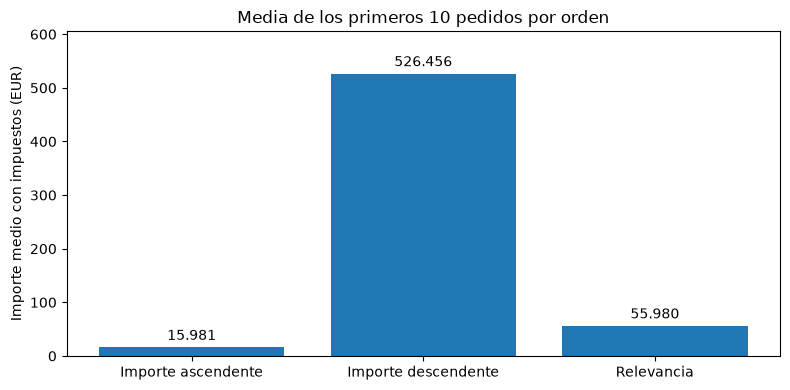

In [37]:
mediciones = [medicion for medicion in (medicion_1, medicion_2, medicion_3) if medicion is not None]

if len(mediciones) != 3 or len({fila[1] for fila in mediciones}) != 1:
    print("Comparación no disponible: se requieren tres mediciones válidas con el mismo total.")
else:
    print(f"{'Orden':<22} {'Coincidencias':>14} {'Observados':>11} {'Media (EUR)':>12}")
    for etiqueta, total, observados, media in mediciones:
        print(f"{etiqueta:<22} {total:>14} {observados:>11} {media:>12.3f}")

    fig, ax = plt.subplots(figsize=(8, 4))
    barras = ax.bar([fila[0] for fila in mediciones], [float(fila[3]) for fila in mediciones])
    ax.bar_label(barras, labels=[f"{fila[3]:.3f}" for fila in mediciones], padding=3)
    ax.margins(y=0.15)
    ax.set(ylabel="Importe medio con impuestos (EUR)", title="Media de los primeros 10 pedidos por orden")
    fig.tight_layout()
    plt.show()

#### Conclusión observada

En el índice local de ejemplo, `clothing` con el filtro `EUR` dio **3927 coincidencias** en las tres consultas. Con 10 pedidos por orden y desempate por `order_id`, las medias fueron **15,981 EUR** (ascendente), **526,456 EUR** (descendente) y **55,980 EUR** (relevancia). La diferencia entre descendente y ascendente fue **510,475 EUR**. La relevancia quedó entre ambos extremos, como preveía la hipótesis.

El orden cambió qué pedidos entraron entre los primeros 10, no sus importes ni el total de coincidencias. Estas medias describen solo esos primeros 10 resultados por orden: no son la media de todos los pedidos coincidentes ni permiten generalizar un efecto causal.

## Anexo: tres demostraciones opcionales

Estas consultas ilustran otras formas de buscar, ordenar y visualizar pedidos. No son mediciones del experimento. Después de la conexión compartida, puedes ejecutar las celdas de cada demostración sin ejecutar las demás.

### Consulta 1: buscar por categoría y ordenar por importe

El índice `kibana_sample_data_ecommerce` contiene pedidos. `match` analiza el texto de `category`; con `operator: and` exige todos los términos analizados, no una frase exacta. `sort` ordena por `taxful_total_price` (importe con impuestos). `size` limita los pedidos devueltos.

Edita estos valores para cambiar la consulta de Python.

In [17]:
termino = "clothing"
orden = "desc"
limite = 10

cuerpo = {
    "size": limite,
    "_source": ["order_id", "category", "taxful_total_price", "currency"],
    "query": {"match": {"category": {"query": termino, "operator": "and"}}},
    "sort": [{"taxful_total_price": {"order": orden}}],
}

#### Ejecución 1

Copia el bloque entero en la consola de Dev Tools para ejecutar la consulta con los valores predeterminados.

```http
GET kibana_sample_data_ecommerce/_search
{
  "size": 10,
  "_source": [
    "order_id",
    "category",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "match": {
      "category": {
        "query": "clothing",
        "operator": "and"
      }
    }
  },
  "sort": [
    {
      "taxful_total_price": {
        "order": "desc"
      }
    }
  ]
}
```

En Jupyter, ejecuta la siguiente celda. Imprime la URL y el JSON efectivos antes de enviar la petición de solo lectura.

In [18]:
resultado = None
try:
    resultado = ejecutar_busqueda(cuerpo, ruta_busqueda)
except HTTPError as error:
    if error.code == 404:
        print(f"No se encontró el índice {indice}. Comprueba que el conjunto de ejemplo esté disponible.")
    else:
        print(f"Elasticsearch respondió con el código HTTP {error.code}. Revisa el índice y la consulta.")
except (URLError, TimeoutError):
    print("No se pudo conectar con Elasticsearch. Revisa la URL y el estado del servicio.")

GET http://elasticsearch:9200/kibana_sample_data_ecommerce/_search
{
  "size": 10,
  "_source": [
    "order_id",
    "category",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "match": {
      "category": {
        "query": "clothing",
        "operator": "and"
      }
    }
  },
  "sort": [
    {
      "taxful_total_price": {
        "order": "desc"
      }
    }
  ]
}


#### Visualización 1

Cada barra representa un pedido. La gráfica conserva el orden de la respuesta de arriba abajo; comprueba que los importes siguen el sentido elegido.

Pedido 739290: Men's Clothing
Pedido 718360: Men's Clothing, Men's Shoes, Men's Accessories
Pedido 714566: Men's Clothing, Men's Shoes, Women's Accessories
Pedido 731279: Women's Clothing, Women's Shoes
Pedido 724489: Women's Clothing, Women's Shoes, Women's Accessories
Pedido 713508: Men's Clothing, Men's Shoes, Men's Accessories
Pedido 719568: Men's Clothing, Men's Shoes, Men's Accessories
Pedido 719317: Men's Clothing
Pedido 721778: Men's Shoes, Men's Clothing
Pedido 718552: Men's Clothing, Men's Shoes


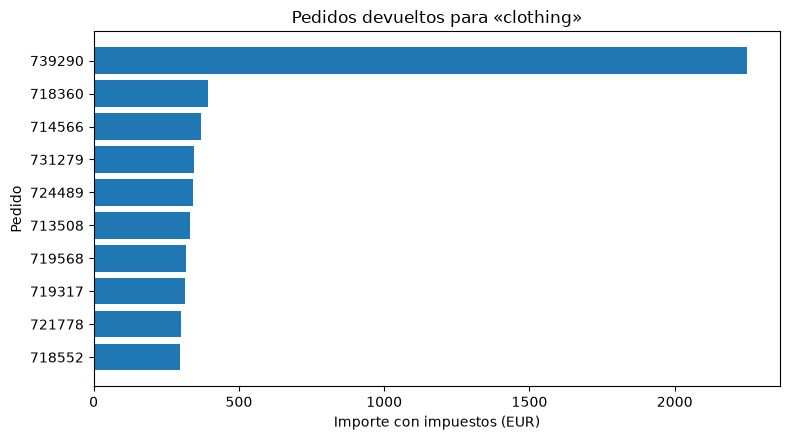

In [19]:
if resultado is not None:
    pedidos = [hit["_source"] for hit in resultado["hits"]["hits"]]
    if not pedidos:
        print("No se encontraron pedidos para el texto indicado.")
    else:
        for pedido in pedidos:
            categorias = ", ".join(pedido["category"])
            print(f'Pedido {pedido["order_id"]}: {categorias}')

        etiquetas = [str(pedido["order_id"]) for pedido in pedidos]
        importes = [pedido["taxful_total_price"] for pedido in pedidos]
        monedas = ", ".join(sorted({pedido["currency"] for pedido in pedidos}))
        fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(pedidos) + 1)))
        ax.barh(range(len(pedidos)), importes)
        ax.set_yticks(range(len(pedidos)), etiquetas)
        ax.invert_yaxis()
        ax.set(xlabel=f"Importe con impuestos ({monedas})", ylabel="Pedido",
               title=f'Pedidos devueltos para «{termino}»')
        fig.tight_layout()
        plt.show()

### Consulta 2: buscar productos en los pedidos más recientes

Busca `shirt` en `products.product_name`. La búsqueda devuelve pedidos, no productos individuales. `order_date` ordena del más reciente al más antiguo.

### Configuración editable

Edita el texto, el orden (`desc` o `asc`) o el máximo de pedidos en Python.

In [20]:
texto_producto = "shirt"
orden_fecha = "desc"
limite_recientes = 10

cuerpo_recientes = {
    "size": limite_recientes,
    "_source": ["order_id", "order_date"],
    "query": {"match": {"products.product_name": {"query": texto_producto, "operator": "and"}}},
    "sort": [{"order_date": {"order": orden_fecha}}],
}

#### Ejecución 2

Copia el bloque completo en Dev Tools para usar los valores predeterminados. Si editas los valores en Python, la celda imprimirá la petición actualizada.

```http
GET kibana_sample_data_ecommerce/_search
{
  "size": 10,
  "_source": [
    "order_id",
    "order_date"
  ],
  "query": {
    "match": {
      "products.product_name": {
        "query": "shirt",
        "operator": "and"
      }
    }
  },
  "sort": [
    {
      "order_date": {
        "order": "desc"
      }
    }
  ]
}
```

En Jupyter, ejecuta la siguiente celda para enviar la petición de solo lectura.

In [21]:
pedidos_recientes = buscar_pedidos(cuerpo_recientes)

GET http://elasticsearch:9200/kibana_sample_data_ecommerce/_search
{
  "size": 10,
  "_source": [
    "order_id",
    "order_date"
  ],
  "query": {
    "match": {
      "products.product_name": {
        "query": "shirt",
        "operator": "and"
      }
    }
  },
  "sort": [
    {
      "order_date": {
        "order": "desc"
      }
    }
  ]
}


#### Visualización 2

Cada punto muestra la fecha y hora de un pedido en UTC. El gráfico conserva el orden de la respuesta de arriba abajo.

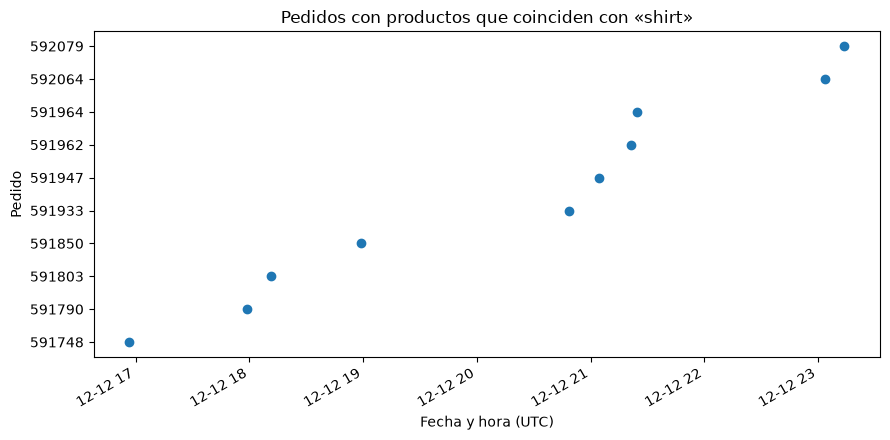

In [22]:
if pedidos_recientes:
    posiciones = range(len(pedidos_recientes))
    fechas = [
        datetime.fromisoformat(pedido["order_date"]).astimezone(timezone.utc)
        for pedido in pedidos_recientes
    ]
    fig, ax = plt.subplots(figsize=(9, max(3, 0.35 * len(pedidos_recientes) + 1)))
    ax.scatter(fechas, posiciones)
    ax.set_yticks(posiciones, [str(pedido["order_id"]) for pedido in pedidos_recientes])
    ax.invert_yaxis()
    ax.set(xlabel="Fecha y hora (UTC)", ylabel="Pedido", title=f'Pedidos con productos que coinciden con «{texto_producto}»')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

### Consulta 3: buscar por categoría dentro de un rango de importes

Busca `clothing` en `category` y limita el importe total del pedido con impuestos a un rango inclusivo. El importe es del pedido completo, no de un producto. `sort` ordena del menor al mayor importe.

### Configuración editable

Edita la categoría, los dos límites del rango, el orden (`asc` o `desc`) o el máximo de pedidos en Python.

In [ ]:
texto_categoria = "clothing"
importe_minimo = 30
importe_maximo = 70
orden_importe = "asc"
limite_importes = 10

cuerpo_importes = {
    "size": limite_importes,
    "_source": ["order_id", "taxful_total_price", "currency"],
    "query": {"bool": {
        "must": [{"match": {"category": {"query": texto_categoria, "operator": "and"}}}],
        "filter": [{"range": {"taxful_total_price": {"gte": importe_minimo, "lte": importe_maximo}}}],
    }},
    "sort": [{"taxful_total_price": {"order": orden_importe}}],
}

#### Ejecución 3

Copia el bloque completo en Dev Tools para usar los valores predeterminados. Si editas los valores en Python, la celda imprimirá la petición actualizada.

```http
GET kibana_sample_data_ecommerce/_search
{
  "size": 10,
  "_source": [
    "order_id",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "bool": {
      "must": [
        {
          "match": {
            "category": {
              "query": "clothing",
              "operator": "and"
            }
          }
        }
      ],
      "filter": [
        {
          "range": {
            "taxful_total_price": {
              "gte": 30,
              "lte": 70
            }
          }
        }
      ]
    }
  },
  "sort": [
    {
      "taxful_total_price": {
        "order": "asc"
      }
    }
  ]
}
```

En Jupyter, ejecuta la siguiente celda para enviar la petición de solo lectura.

In [ ]:
pedidos_importes = buscar_pedidos(cuerpo_importes)

#### Visualización 3

Cada punto muestra el importe de un pedido. La zona sombreada indica el rango elegido y las etiquetas indican la moneda de cada pedido; la consulta no convierte monedas.

In [ ]:
if pedidos_importes:
    posiciones = range(len(pedidos_importes))
    importes = [pedido["taxful_total_price"] for pedido in pedidos_importes]
    etiquetas = [f'{pedido["order_id"]} ({pedido["currency"]})' for pedido in pedidos_importes]
    fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(pedidos_importes) + 1)))
    ax.axvspan(importe_minimo, importe_maximo, alpha=0.15, label="Rango solicitado")
    ax.scatter(importes, posiciones)
    ax.set_yticks(posiciones, etiquetas)
    ax.invert_yaxis()
    ax.set(xlabel="Importe con impuestos", ylabel="Pedido (moneda)", title=f'Pedidos de la categoría «{texto_categoria}»')
    ax.legend()
    fig.tight_layout()
    plt.show()